# Wildfire Album: EIC Messages and Source Data

Issue #29. Follows [notebook-guide.md](../docs/notebook-guide.md) and [data-guide.md](../docs/data-guide.md).

**The album's message, in EIC's words** ([40531](https://svs.gsfc.nasa.gov/40531/), [5453](https://svs.gsfc.nasa.gov/5453/)):

> Climate change continues to cause longer fire seasons and more severe wildfires.

> The extent of area burned by wildfires each year appears to have increased since the 1980s. … of the 10 years with the largest acreage burned, all have occurred since 2004, including the peak years in 2015 and 2020.

**The story this notebook checks:**

1. **National graph (5453)**: US annual burned acres 1983–2024 from NIFC, and whether the ten largest years all fall after 2004.
   **Where each year burned**: NIFC has no locations, so the globe shows each year's large fires from MTBS (USGS/USFS) where they burned.
2. **A peak year on the map**: 2020 large fires from NASA FEDS (cited on EIC wildfire pages such as 5639), so the globe can show where fire sat in a peak year named by 5453.

Track candidates: (1) annual acres as a literal graph-sonification, with each year's MTBS large fires on the globe; (2) 2020 daily active large-fire area / count for the globe.

Run with `npm run notebook`. Downloads go to `data/wildfire/raw/` (local only). NIFC, MTBS and the FEDS VEDA API are public; no login is needed.


In [1]:
import html
import json
import re
import time
import zipfile
import urllib.parse
from datetime import date, datetime, timedelta, timezone
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
import pandas as pd
import requests
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/wildfire/raw")
TRACKS = Path("../data/wildfire/tracks")
(RAW / "api").mkdir(parents=True, exist_ok=True)
(RAW / "feds").mkdir(parents=True, exist_ok=True)
(RAW / "nifc").mkdir(parents=True, exist_ok=True)
(RAW / "mtbs").mkdir(parents=True, exist_ok=True)
TRACKS.mkdir(parents=True, exist_ok=True)


def download(name, url, session=None):
    path = RAW / name
    if not path.exists():
        response = (session or requests).get(url, timeout=120)
        response.raise_for_status()
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(response.content)
    return path


def svs_page(page_id):
    return json.loads(download(f"api/{page_id}.json", f"https://svs.gsfc.nasa.gov/api/{page_id}").read_text())


def plain(text):
    return html.unescape(re.sub(r"<[^>]+>", "", text or "")).strip()


def source_note(ax, text):
    ax.annotate(text, xy=(0, -0.22), xycoords="axes fraction", fontsize=8, color="gray")


## 1. Links

Everything this notebook reads, in one place. The tables are built from the SVS API.


In [2]:
EIC_GALLERY = 40467
PAGES = [40531, 5453, 5639]


def gallery_paths(gallery_id):
    gallery = svs_page(gallery_id)
    paths = {}
    stack = [(gallery.get("title") or "EIC", gallery)]
    while stack:
        prefix, node = stack.pop()
        for child_id in node.get("gallery_items") or node.get("items") or []:
            pass
        # SVS gallery JSON varies; fall back to a fixed path note when walk is empty.
    fixed = {
        40531: "EIC Dashboards → Wildland Fires Dashboard → 40531",
        5453: "EIC Dashboards → Wildland Fires Dashboard → 5453",
        5639: "EIC / wildfire daily visualizations → 5639",
    }
    return fixed


paths = gallery_paths(EIC_GALLERY)
rows = []
for page_id in PAGES:
    page = svs_page(page_id)
    rows.append(
        {
            "page": page_id,
            "title": page.get("title"),
            "gallery path": paths.get(page_id, ""),
            "SVS page": f"https://svs.gsfc.nasa.gov/{page_id}/",
            "SVS API": f"https://svs.gsfc.nasa.gov/api/{page_id}",
        }
    )
display(Markdown("### 1.1 EIC pages"))
display(pd.DataFrame(rows))


### 1.1 EIC pages

,page,title,gallery path,SVS page,SVS API
0,40531,Wildland Fires Dashboard,EIC Dashboards → Wildland Fires Dashboard → 40531,https://svs.gsfc.nasa.gov/40531/,https://svs.gsfc.nasa.gov/api/40531
1,5453,Annual Wildfire Burned Area in the United States,EIC Dashboards → Wildland Fires Dashboard → 5453,https://svs.gsfc.nasa.gov/5453/,https://svs.gsfc.nasa.gov/api/5453
2,5639,Daily Visualizations of the Largest Wildfires in the United States: 2026,EIC / wildfire daily visualizations → 5639,https://svs.gsfc.nasa.gov/5639/,https://svs.gsfc.nasa.gov/api/5639


### 1.2 What each page cites, and what this notebook downloads

- **Cited by EIC** comes from the `datasets` field of each page.
- When EIC gives no download link, we use a substitute and say why.


In [3]:
MTBS_FOD_URL = "https://edcintl.cr.usgs.gov/downloads/sciweb1/shared/MTBS_Fire/data/composite_data/fod_pt_shapefile/mtbs_fod_pts_data.zip"


def cited(page_id):
    out = []
    for d in svs_page(page_id).get("datasets") or []:
        name = d.get("name") or d.get("common_name") or "(unnamed)"
        url = d.get("url") or d.get("doi") or ""
        out.append({"page": page_id, "cited by EIC": name, "cited URL": url or "(no url)"})
    return out


cite_rows = []
for page_id in PAGES:
    cite_rows.extend(cited(page_id) or [{"page": page_id, "cited by EIC": "(none)", "cited URL": ""}])
display(pd.DataFrame(cite_rows))

downloads = pd.DataFrame(
    [
        {
            "used for": "Track 1 annual acres",
            "file": "nifc/wildfires.html",
            "downloaded URL": "https://www.nifc.gov/fire-information/statistics/wildfires",
            "note": "Cited by 5453 (NIFC). Page HTML; table parsed below.",
        },
        {
            "used for": "Track 1 globe: each year's large fires",
            "file": "mtbs/mtbs_fod_pts_data.zip",
            "downloaded URL": MTBS_FOD_URL,
            "note": "Not cited by EIC. Substitute spatial source: NIFC has no locations. MTBS maps every large US fire since 1984 (≥1,000 acres in the West, ≥500 in the East).",
        },
        {
            "used for": "Track 2 2020 globe / daily series",
            "file": "feds/feds_2020_light.csv",
            "downloaded URL": "https://openveda.cloud/api/features/collections/public.eis_fire_lf_perimeter_archive/items",
            "note": "Substitute spatial source: 5453 has no coordinates. FEDS is cited on EIC 5639 and related wildfire pages. Filter farea>50 km², year 2020.",
        },
    ]
)
display(Markdown("### Downloads"))
display(downloads)


,page,cited by EIC,cited URL
0,40531,(none),
1,5453,United States Total Wildland Fires and Acres,https://www.nifc.gov/fire-information/statistics/wildfires
2,5639,GEOS Atmospheric Model,(no url)
3,5639,GEOS Forward Processing 2Km Replay,(no url)
4,5639,GEOS Composition Forecast,https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/
5,5639,GEOS-FP,https://fluid.nccs.nasa.gov/weather/
6,5639,Fire Events Data Suite,https://earth-information-system.github.io/fireatlas/docs/nrt.html
7,5639,FEDS OGC API,https://earth-information-system.github.io/fireatlas/docs/nrt.html
8,5639,Quick Fire Emissions Dataset,https://ntrs.nasa.gov/citations/20180005253
9,5639,Earth Observatory Natural Event Tracker API,https://eonet.gsfc.nasa.gov/


### Downloads

,used for,file,downloaded URL,note
0,Track 1 annual acres,nifc/wildfires.html,https://www.nifc.gov/fire-information/statistics/wildfires,Cited by 5453 (NIFC). Page HTML; table parsed below.
1,Track 1 globe: each year's large fires,mtbs/mtbs_fod_pts_data.zip,https://edcintl.cr.usgs.gov/downloads/sciweb1/shared/MTBS_Fire/data/composite_data/fod_pt_shapefile/mtbs_fod_pts_dat...,"Not cited by EIC. Substitute spatial source: NIFC has no locations. MTBS maps every large US fire since 1984 (≥1,000..."
2,Track 2 2020 globe / daily series,feds/feds_2020_light.csv,https://openveda.cloud/api/features/collections/public.eis_fire_lf_perimeter_archive/items,Substitute spatial source: 5453 has no coordinates. FEDS is cited on EIC 5639 and related wildfire pages. Filter far...


## 2. What EIC says

The message of each page, taken from its description (or a media caption when that holds the claim).


In [4]:
def message(page_id):
    page = svs_page(page_id)
    text = plain(page.get("description") or "").split(" || ")[0]
    if len(text) < 80:
        for g in page.get("media_groups") or []:
            cap = plain(g.get("description") or "")
            if len(cap) > len(text):
                text = cap
    return text


for page_id in PAGES:
    display(Markdown(f"### [{page_id}](https://svs.gsfc.nasa.gov/{page_id}/) {svs_page(page_id).get('title')}"))
    display(Markdown(f"> {message(page_id)[:900]}"))


### [40531](https://svs.gsfc.nasa.gov/40531/) Wildland Fires Dashboard

> Climate change continues to cause longer fire seasons and more severe wildfires. NASA's Earth observing satellites and its robust network of interagency partners work together to help communities manage the impacts of fire, and reduce risks before, during and after fire events.

### [5453](https://svs.gsfc.nasa.gov/5453/) Annual Wildfire Burned Area in the United States

> A graph of annual wildfire burned area in the United States between the years 1983 and 2024.

### [5639](https://svs.gsfc.nasa.gov/5639/) Daily Visualizations of the Largest Wildfires in the United States: 2026

> Wildland fires pose significant threats to ecosystems, property, and human lives. Leveraging NASA’s satellite data, advanced models, visualization capacity and computing power, we analyze fire events, monitor how weather conditions impact fires and how regional air quality affects communities. Through this webpage we offer daily updated visualizations of the two largest active wildfires events in the continental United States throughout fire season.

## 3. Source data: US annual wildfire acres (5453 / NIFC)

[5453](https://svs.gsfc.nasa.gov/5453/) · [NIFC wildfires and acres](https://www.nifc.gov/fire-information/statistics/wildfires)


In [5]:
nifc_html = download("nifc/wildfires.html", "https://www.nifc.gov/fire-information/statistics/wildfires")
raw_table = pd.read_html(StringIO(nifc_html.read_text(errors="ignore")), header=None)[0]
# Row 2 is the header (Year, Fires, Acres); data starts at row 3.
nifc = raw_table.iloc[3:].copy()
nifc.columns = ["Year", "Fires", "Acres"]
nifc["Year"] = pd.to_numeric(nifc["Year"], errors="coerce")
# NIFC marks 2004 with "*" (its footnote: 2004 fires and acres do not include state lands for North Carolina), so
# strip it with the thousands commas; otherwise the year fails to parse and drops out.
nifc["Fires"] = pd.to_numeric(nifc["Fires"].astype(str).str.replace(r"[,*]", "", regex=True), errors="coerce")
nifc["Acres"] = pd.to_numeric(nifc["Acres"].astype(str).str.replace(r"[,*]", "", regex=True), errors="coerce")
nifc = nifc.dropna().astype({"Year": int, "Fires": int, "Acres": int})
nifc = nifc.sort_values("Year").reset_index(drop=True)
assert nifc.Year.diff().dropna().eq(1).all(), "a year is missing from the NIFC table"
nifc["acres_per_fire"] = nifc["Acres"] / nifc["Fires"]
nifc.to_csv(RAW / "nifc/nifc_annual.csv", index=False)
nifc.tail()


,Year,Fires,Acres,acres_per_fire
38,2021,58985,7125643,120.804323
39,2022,68988,7577183,109.833348
40,2023,56580,2693910,47.612407
41,2024,64897,8924884,137.523830
42,2025,77850,5131474,65.914888


## 4. Message check: burned area up since the 1980s; top 10 years all since 2004


mean acres 1983–99 (M): 2.98
mean acres 2015–24 (M): 7.55
top 10 years all >= 2004? True


,Year,Fires,Acres
32,2015,68151,10125149
37,2020,58950,10122336
34,2017,71499,10026086
23,2006,96385,9873745
24,2007,85705,9328045
29,2012,67774,9326238
41,2024,64897,8924884
35,2018,58083,8767492
28,2011,74126,8711367
22,2005,66753,8689389


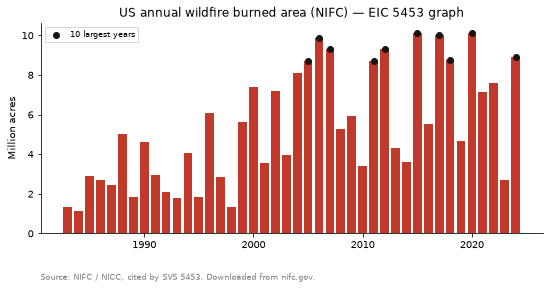

In [6]:
claim = nifc[nifc.Year <= 2024].copy()
top10 = claim.nlargest(10, "Acres")
early = claim[claim.Year <= 1999].Acres.mean()
late = claim[claim.Year >= 2015].Acres.mean()
print("mean acres 1983–99 (M):", round(early / 1e6, 2))
print("mean acres 2015–24 (M):", round(late / 1e6, 2))
print("top 10 years all >= 2004?", bool((top10.Year >= 2004).all()))
display(top10[["Year", "Fires", "Acres"]])

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(claim.Year, claim.Acres / 1e6, color="#c0392b", width=0.8)
ax.scatter(top10.Year, top10.Acres / 1e6, color="#1a1410", zorder=3, label="10 largest years")
ax.set_ylabel("Million acres")
ax.set_title("US annual wildfire burned area (NIFC) — EIC 5453 graph")
ax.legend(fontsize=8)
source_note(ax, "Source: NIFC / NICC, cited by SVS 5453. Downloaded from nifc.gov.")
plt.show()


### 4.1 Where each year burned (MTBS)

[MTBS burned area boundaries, fire occurrence points](https://www.mtbs.gov/direct-download) · [download](https://edcintl.cr.usgs.gov/downloads/sciweb1/shared/MTBS_Fire/data/composite_data/fod_pt_shapefile/mtbs_fod_pts_data.zip)

NIFC's table has no locations, so on its own it cannot put a year on the globe. **Ours, not EIC's:** Monitoring Trends in Burn Severity (MTBS, USGS and USDA Forest Service) maps every large US fire since 1984 from Landsat: at least 1,000 acres in the West and 500 in the East. Each fire comes with its burned-area acres, its ignition date and a point inside its boundary.

We keep the fires MTBS types as wildfires (`Wildfire` and `Wildland Fire Use`) and leave out prescribed burns and fires of unknown type, then check how much of NIFC's acres they hold each year. MTBS starts in 1984, so 1983 has no map. It also leaves out the many small fires NIFC counts, so the map holds most of a year's acres, not all.


MTBS fires: 31514


,fires
incid_type,
Wildfire,17040
Prescribed Fire,9957
Other,4311
Wildland Fire Use,203
Unknown,2
Complex,1


years mapped: 41 of 42 (MTBS starts in 1984)
median share of NIFC acres mapped: 81%
correlation of MTBS and NIFC annual acres: 0.977
10 largest NIFC years, 10 largest MTBS years: [2005, 2006, 2007, 2011, 2012, 2015, 2017, 2018, 2020, 2024] [2004, 2005, 2006, 2007, 2011, 2012, 2015, 2017, 2018, 2020]


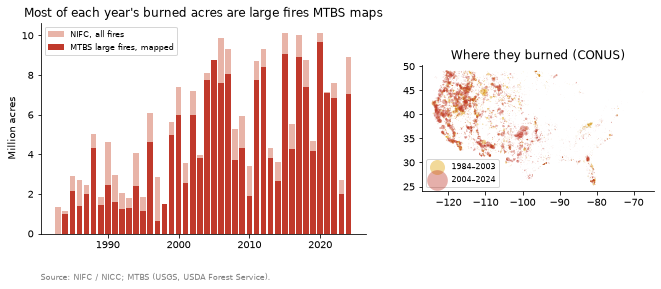

In [7]:
mtbs_zip = download("mtbs/mtbs_fod_pts_data.zip", MTBS_FOD_URL)
with zipfile.ZipFile(mtbs_zip) as z:
    z.extractall(RAW / "mtbs")
mtbs_all = gpd.read_file(RAW / "mtbs/mtbs_FODpoints_DD.shp")
print("MTBS fires:", len(mtbs_all))
display(mtbs_all.incid_type.value_counts().to_frame("fires"))

WILDFIRE_TYPES = ["Wildfire", "Wildland Fire Use"]
mtbs = pd.DataFrame(
    {
        "ig_date": pd.to_datetime(mtbs_all.ig_date),
        "acres": pd.to_numeric(mtbs_all.burnbndac),
        "lon": pd.to_numeric(mtbs_all.burnbndlon),
        "lat": pd.to_numeric(mtbs_all.burnbndlat),
        "type": mtbs_all.incid_type,
    }
)
mtbs["year"] = mtbs.ig_date.dt.year
mtbs = mtbs[mtbs.type.isin(WILDFIRE_TYPES) & mtbs.year.between(claim.Year.min(), claim.Year.max())]
mtbs = mtbs.sort_values(["year", "ig_date"]).reset_index(drop=True)

mapped = mtbs.groupby("year").agg(fires=("acres", "size"), acres=("acres", "sum"))
coverage = claim.set_index("Year")[["Acres"]].join(mapped, how="left")
coverage["share_of_nifc"] = coverage.acres / coverage.Acres
print("years mapped:", int(coverage.acres.notna().sum()), "of", len(coverage), "(MTBS starts in 1984)")
print("median share of NIFC acres mapped:", f"{coverage.share_of_nifc.median():.0%}")
print("correlation of MTBS and NIFC annual acres:", round(coverage.dropna()[["Acres", "acres"]].corr().iloc[0, 1], 3))
print("10 largest NIFC years, 10 largest MTBS years:", sorted(coverage.Acres.nlargest(10).index), sorted(coverage.acres.nlargest(10).index))

fig, (ax, ax_map) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
ax.bar(coverage.index, coverage.Acres / 1e6, color="#e8b4a8", width=0.8, label="NIFC, all fires")
ax.bar(coverage.index, coverage.acres / 1e6, color="#c0392b", width=0.8, label="MTBS large fires, mapped")
ax.set_ylabel("Million acres")
ax.set_title("Most of each year's burned acres are large fires MTBS maps")
ax.legend(fontsize=8)
source_note(ax, "Source: NIFC / NICC; MTBS (USGS, USDA Forest Service).")
conus = mtbs[mtbs.lon.between(-125, -66) & mtbs.lat.between(24, 50)]
for years, color in (((1984, 2003), "#e0a000"), ((2004, 2024), "#c0392b")):
    part = conus[conus.year.between(*years)]
    ax_map.scatter(part.lon, part.lat, s=part.acres / 2e4, color=color, alpha=0.4, lw=0, label=f"{years[0]}–{years[1]}")
ax_map.set_aspect(1.3)
ax_map.set_title("Where they burned (CONUS)")
ax_map.legend(fontsize=8, markerscale=4)
plt.show()


## 5. Source data: 2020 large fires on the map (FEDS via VEDA)

[5639](https://svs.gsfc.nasa.gov/5639/) lists Fire Events Data Suite / FEDS OGC API. We use the public VEDA Features collection `public.eis_fire_lf_perimeter_archive` for 2020, keeping observations with `farea > 50` km² so the globe stays readable.

**Why this instead of 5453 alone:** NIFC has no locations. FEDS gives fire perimeters with coordinates so Track 2 can put a peak year on the globe.

If `feds/feds_2020_light.csv` is already present under `raw/`, the fetch is skipped.


In [8]:
FEDS_ITEMS = "https://openveda.cloud/api/features/collections/public.eis_fire_lf_perimeter_archive/items"
LIGHT = RAW / "feds/feds_2020_light.csv"


def centroid(geom):
    coords = geom.get("coordinates")
    pts = []

    def walk(c):
        if isinstance(c[0], (int, float)):
            pts.append(c)
            return
        for x in c:
            walk(x)

    walk(coords)
    if not pts:
        return None, None
    return float(np.mean([p[0] for p in pts])), float(np.mean([p[1] for p in pts]))


def fetch_window(start, end, min_farea=50.0, page_size=50):
    rows, offset, matched = [], 0, None
    while True:
        q = urllib.parse.urlencode(
            {"limit": page_size, "offset": offset, "datetime": f"{start}/{end}", "filter": f"farea>{min_farea}"}
        )
        url = f"{FEDS_ITEMS}?{q}"
        data = None
        for attempt in range(8):
            try:
                data = requests.get(url, timeout=120).json()
                break
            except Exception as e:
                time.sleep(min(20, 1.5 * (attempt + 1)))
        if data is None:
            break
        if matched is None:
            matched = int(data.get("numberMatched") or 0)
        feats = data.get("features") or []
        if not feats:
            break
        for f in feats:
            p = f.get("properties") or {}
            lon, lat = centroid(f.get("geometry") or {})
            rows.append(
                {
                    "t": p.get("t"),
                    "fireid": p.get("fireid"),
                    "farea": p.get("farea"),
                    "flinelen": p.get("flinelen"),
                    "meanfrp": p.get("meanfrp"),
                    "n_newpixels": p.get("n_newpixels"),
                    "lon": lon,
                    "lat": lat,
                }
            )
        offset += len(feats)
        if offset >= matched or len(feats) < page_size:
            break
        time.sleep(0.05)
    return rows


if LIGHT.exists() and LIGHT.stat().st_size > 50_000:
    feds = pd.read_csv(LIGHT, parse_dates=["t"])
    print("reuse", LIGHT, "rows", len(feds))
else:
    rows = []
    cur = datetime(2020, 1, 1, tzinfo=timezone.utc)
    end = datetime(2020, 12, 31, 23, 59, 59, tzinfo=timezone.utc)
    while cur < end:
        nxt = min(cur + timedelta(days=7), end + timedelta(seconds=1))
        start_s = cur.strftime("%Y-%m-%dT%H:%M:%SZ")
        end_s = (nxt - timedelta(seconds=1)).strftime("%Y-%m-%dT%H:%M:%SZ")
        part = fetch_window(start_s, end_s)
        rows.extend(part)
        if part:
            print(start_s[:10], "cumulative", len(rows))
        cur = nxt
    feds = pd.DataFrame(rows)
    feds["t"] = pd.to_datetime(feds["t"])
    feds = feds.drop_duplicates(subset=["fireid", "t"])
    feds.to_csv(LIGHT, index=False)
    print("wrote", LIGHT, "rows", len(feds), "fires", feds.fireid.nunique())

feds.head()


reuse ../data/wildfire/raw/feds/feds_2020_light.csv rows 6739


,t,fireid,farea,flinelen,meanfrp,n_newpixels,n_pixels,duration,lon,lat
0,2020-06-02 00:00:00,F7521,71.916215,7.428387,3.450833,12,274,2.0,-111.294859,33.384638
1,2020-06-02 12:00:00,F7521,77.379287,9.152835,10.941290,31,305,2.5,-111.296218,33.382936
2,2020-06-01 12:00:00,F7521,68.058577,23.051391,7.638866,97,262,1.5,-111.294277,33.380679
3,2020-06-09 12:00:00,F7814,111.585777,0.000000,5.230000,3,408,3.0,-110.352520,33.497791
4,2020-06-09 00:00:00,F7814,111.585777,20.790363,2.532391,92,405,2.5,-110.352520,33.497791


days 214 unique large fires 100
peak day 2020-09-16 area_km2 21912.5


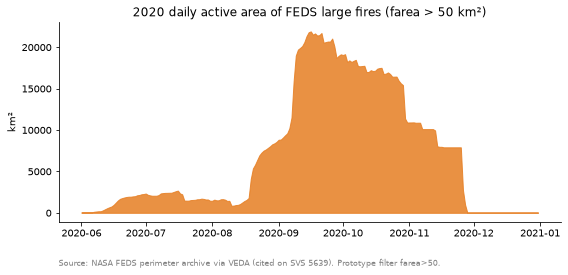

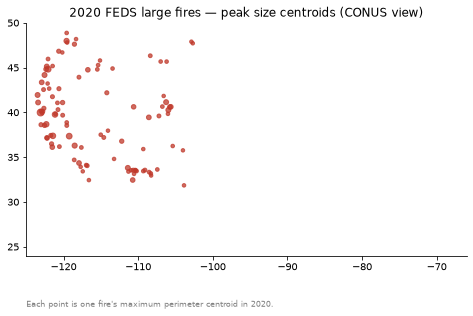

In [9]:
feds = feds.copy()
feds["day"] = feds["t"].dt.floor("D")
per_day_fire = feds.sort_values(["fireid", "day", "farea"]).groupby(["fireid", "day"], as_index=False).tail(1)
daily = (
    per_day_fire.groupby("day")
    .agg(
        n_fires=("fireid", "nunique"),
        area_km2=("farea", "sum"),
        flinelen=("flinelen", "sum"),
        meanfrp=("meanfrp", "mean"),
        lon=("lon", "mean"),
        lat=("lat", "mean"),
    )
    .reset_index()
)
full = pd.date_range(daily.day.min(), daily.day.max(), freq="D")
daily = daily.set_index("day").reindex(full).fillna(0).rename_axis("day").reset_index()
daily.to_csv(RAW / "feds/feds_2020_daily.csv", index=False)

peak_fire = feds.sort_values("farea").groupby("fireid", as_index=False).tail(1)
peak_fire = peak_fire[peak_fire.farea >= 50]
peak_fire.to_csv(RAW / "feds/feds_2020_globe_fires.csv", index=False)
busy = daily.loc[daily.area_km2.idxmax(), "day"]
peak_day = per_day_fire[per_day_fire.day == busy]
peak_day.to_csv(RAW / "feds/feds_2020_peakday_fires.csv", index=False)

print("days", len(daily), "unique large fires", peak_fire.fireid.nunique())
print("peak day", pd.Timestamp(busy).date(), "area_km2", round(float(daily.loc[daily.day == busy, "area_km2"].iloc[0]), 1))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.fill_between(daily.day, daily.area_km2, color="#e67e22", alpha=0.85)
ax.set_title("2020 daily active area of FEDS large fires (farea > 50 km²)")
ax.set_ylabel("km²")
source_note(ax, "Source: NASA FEDS perimeter archive via VEDA (cited on SVS 5639). Prototype filter farea>50.")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(peak_fire.lon, peak_fire.lat, s=8 + 40 * np.sqrt(peak_fire.farea / peak_fire.farea.max()), c="#c0392b", alpha=0.75)
ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_aspect(1.2)
ax.set_title("2020 FEDS large fires — peak size centroids (CONUS view)")
source_note(ax, "Each point is one fire's maximum perimeter centroid in 2020.")
plt.show()


## 6. Message summary


In [10]:
summary = pd.DataFrame(
    [
        {
            "EIC": 40531,
            "message": "Longer fire seasons and more severe wildfires",
            "key number": "(dashboard framing)",
            "track data": "context for album mood",
        },
        {
            "EIC": 5453,
            "message": "Annual burned area up since 1980s; top 10 years all since 2004 (peaks 2015, 2020)",
            "key number": f"top10 since 2004 = {(top10.Year >= 2004).all()}; 2020 acres = {int(claim.loc[claim.Year==2020,'Acres'].iloc[0]):,}",
            "track data": "nifc annual acres → Track 1",
        },
        {
            "EIC": "5639 / FEDS",
            "message": "Spatial fire events for a peak year on the globe",
            "key number": f"2020 peak day {pd.Timestamp(busy).date()} ≈ {float(daily.area_km2.max()):.0f} km² active large-fire area",
            "track data": "FEDS 2020 daily + fire points → Track 2",
        },
    ]
)
display(summary)


,EIC,message,key number,track data
0,40531,Longer fire seasons and more severe wildfires,(dashboard framing),context for album mood
1,5453,"Annual burned area up since 1980s; top 10 years all since 2004 (peaks 2015, 2020)","top10 since 2004 = True; 2020 acres = 10,122,336",nifc annual acres → Track 1
2,5639 / FEDS,Spatial fire events for a peak year on the globe,2020 peak day 2020-09-16 ≈ 21912 km² active large-fire area,FEDS 2020 daily + fire points → Track 2


## 7. Track candidates

Export the series the album can play. Sound and globe wiring come after this notebook's analysis.


In [11]:
# Track 1: annual US burned acres (through 2024 to match EIC 5453 wording used in the issue)
t1 = claim[["Year", "Fires", "Acres", "acres_per_fire"]].copy()
t1["is_top10"] = t1.Year.isin(top10.Year)
t1.to_csv(TRACKS / "us_annual_burned_acres.csv", index=False)

# Globe for Track 1: each year's MTBS large fires where they burned, in order of ignition, so the globe can light them
# through the year's bar. A point is enough at the label's size: the scar is drawn as large as the fire's acres.
t1_fires = mtbs[["year", "ig_date", "acres", "lon", "lat"]].copy()
t1_fires["ig_date"] = t1_fires.ig_date.dt.strftime("%Y-%m-%d")
t1_fires.to_csv(TRACKS / "mtbs_large_fires.csv", index=False, float_format="%.3f")

# Track 2: 2020 daily large-fire activity, through the last day a large fire still burns (no newly burning pixels
# after 7 November), so the track does not end on weeks of cold scars.
SEASON_END = "2020-11-07"
t2 = daily[daily.day <= SEASON_END].copy()
t2.to_csv(TRACKS / "feds_2020_daily_large_fires.csv", index=False)

# Globe for Track 2: each large fire day by day, at the centroid of its largest perimeter so it stays put. area_km2 is
# the fire's largest perimeter that day; new_pixels sums the newly burning VIIRS pixels FEDS saw that day, so it says
# how hard the fire was burning, not only how big it was.
fire_days = (
    feds[feds.fireid.isin(peak_fire.fireid) & (feds.day <= SEASON_END)]
    .groupby(["day", "fireid"], as_index=False)
    .agg(area_km2=("farea", "max"), new_pixels=("n_newpixels", "sum"))
    .merge(peak_fire[["fireid", "lon", "lat"]], on="fireid")
    .sort_values(["day", "fireid"])
)
fire_days["day"] = fire_days["day"].dt.strftime("%Y-%m-%d")
fire_days["new_pixels"] = fire_days["new_pixels"].astype(int)
fire_days.to_csv(TRACKS / "feds_2020_fire_days.csv", index=False, float_format="%.4f")
old_centroids = TRACKS / "feds_2020_fire_centroids.csv"
if old_centroids.exists():
    old_centroids.unlink()

def downloaded(name):
    """The day the raw file was downloaded (its file date), not the day this cell runs."""
    return str(date.fromtimestamp((RAW / name).stat().st_mtime))


tracks = [
    {
        "id": "us_annual_burned_acres",
        "title": "Burned Acres",
        "file": "us_annual_burned_acres.csv",
        "globe_file": "mtbs_large_fires.csv",
        "duration_hint_s": 30,
        "message": "US annual wildfire burned area has increased since the 1980s; all ten largest years are since 2004.",
        "note": "Ours: the globe shows each year's MTBS large fires (Wildfire and Wildland Fire Use, 1984–2024) where they burned; the music and the read-out play NIFC's national acres. MTBS has no 1983.",
        "eic": [{"id": 5453, "title": svs_page(5453).get("title"), "url": "https://svs.gsfc.nasa.gov/5453/"}],
        "sources": [
            {
                "name": "United States Total Wildland Fires and Acres",
                "provider": "NIFC / NICC",
                "url": "https://www.nifc.gov/fire-information/statistics/wildfires",
                "download_date": downloaded("nifc/wildfires.html"),
                "license": "US federal public information",
                "substitute": None,
            },
            {
                "name": "MTBS Burned Area Boundaries, fire occurrence points",
                "provider": "MTBS (USGS EROS, USDA Forest Service)",
                "url": "https://www.mtbs.gov/direct-download",
                "download_url": MTBS_FOD_URL,
                "download_date": downloaded("mtbs/mtbs_fod_pts_data.zip"),
                "license": "US federal public domain",
                "substitute": "Not cited by EIC. NIFC (cited by 5453) has no locations; MTBS maps the large fires behind most of each year's acres.",
            },
        ],
    },
    {
        "id": "feds_2020_season",
        "title": "2020 Fire Season",
        "file": "feds_2020_daily_large_fires.csv",
        "globe_file": "feds_2020_fire_days.csv",
        "duration_hint_s": 29,
        "message": "In 2020, one of 5453's peak years, large FEDS fires spread across the CONUS; active large-fire area peaked in mid-September.",
        "eic": [
            {"id": 5453, "title": svs_page(5453).get("title"), "url": "https://svs.gsfc.nasa.gov/5453/"},
            {"id": 5639, "title": svs_page(5639).get("title"), "url": "https://svs.gsfc.nasa.gov/5639/"},
        ],
        "sources": [
            {
                "name": "Fire Events Data Suite (FEDS) perimeter archive",
                "provider": "NASA EIS / VEDA",
                "url": "https://openveda.cloud/api/features/collections/public.eis_fire_lf_perimeter_archive",
                "download_date": downloaded("feds/feds_2020_light.csv"),
                "license": "NASA open data via VEDA",
                "substitute": "5453/NIFC has no coordinates. FEDS is listed under datasets on EIC 5639 and related wildfire pages. Prototype keeps farea>50 km² for 2020.",
            }
        ],
    },
]
(TRACKS / "tracks.json").write_text(json.dumps(tracks, indent=2, ensure_ascii=False) + "\n")
print("exported:")
for p in sorted(TRACKS.iterdir()):
    print(" ", p.name, f"{p.stat().st_size/1024:.1f} KB")


exported:
  feds_2020_daily_large_fires.csv 20.8 KB
  feds_2020_fire_days.csv 156.9 KB
  mtbs_large_fires.csv 611.7 KB
  tracks.json 2.7 KB
  us_annual_burned_acres.csv 1.8 KB
